In [55]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

df = pd.read_csv("personality_dataset.csv")

df.head()

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,No,4.0,6.0,No,13.0,5.0,Extrovert
1,9.0,Yes,0.0,0.0,Yes,0.0,3.0,Introvert
2,9.0,Yes,1.0,2.0,Yes,5.0,2.0,Introvert
3,0.0,No,6.0,7.0,No,14.0,8.0,Extrovert
4,3.0,No,9.0,4.0,No,8.0,5.0,Extrovert


In [56]:
print("Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nInformation:")
df.info()

print("\nMissing values:")
print(df.isna().sum())

print("\nFirst rows:")
print(df.head())

Shape:
(2900, 8)

Columns:
Index(['Time_spent_Alone', 'Stage_fear', 'Social_event_attendance',
       'Going_outside', 'Drained_after_socializing', 'Friends_circle_size',
       'Post_frequency', 'Personality'],
      dtype='str')

Information:
<class 'pandas.DataFrame'>
RangeIndex: 2900 entries, 0 to 2899
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time_spent_Alone           2837 non-null   float64
 1   Stage_fear                 2827 non-null   str    
 2   Social_event_attendance    2838 non-null   float64
 3   Going_outside              2834 non-null   float64
 4   Drained_after_socializing  2848 non-null   str    
 5   Friends_circle_size        2823 non-null   float64
 6   Post_frequency             2835 non-null   float64
 7   Personality                2900 non-null   str    
dtypes: float64(5), str(3)
memory usage: 181.4 KB

Missing values:
Time_spent_Alone             63
S

In [57]:
print(df["Personality"].value_counts(dropna=False))

Personality
Extrovert    1491
Introvert    1409
Name: count, dtype: int64


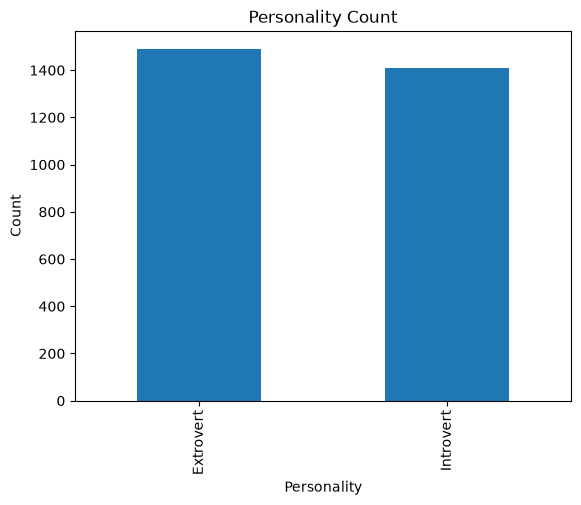

In [58]:
df["Personality"].value_counts().plot(kind="bar")

plt.title("Personality Count")
plt.xlabel("Personality")
plt.ylabel("Count")

plt.show()

In [59]:
numeric_columns = [
    "Time_spent_Alone",
    "Social_event_attendance",
    "Going_outside",
    "Friends_circle_size",
    "Post_frequency"
]

text_columns = [
    "Stage_fear",
    "Drained_after_socializing"
]

# تبدیل ستون‌های عددی به نوع عددی
for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# پر کردن داده‌های خالی عددی با میانه
for column in numeric_columns:
    df[column] = df[column].fillna(
        df[column].median()
    )

# مرتب کردن نوشته‌ها
for column in text_columns:
    df[column] = df[column].astype("string").str.strip().str.title()

# پر کردن داده‌های خالی متنی با پرتکرارترین مقدار
for column in text_columns:
    mode_values = df[column].mode()

    if not mode_values.empty:
        df[column] = df[column].fillna(mode_values.iloc[0])

# مرتب کردن ستون شخصیت
df["Personality"] = (
    df["Personality"]
    .astype("string")
    .str.strip()
    .str.title()
)

# بررسی مقادیر خالی
print(df.isna().sum())

Time_spent_Alone             0
Stage_fear                   0
Social_event_attendance      0
Going_outside                0
Drained_after_socializing    0
Friends_circle_size          0
Post_frequency               0
Personality                  0
dtype: int64


In [60]:
df["Stage_fear"] = df["Stage_fear"].map({
    "No": 0,
    "Yes": 1
})

df["Drained_after_socializing"] = df[
    "Drained_after_socializing"
].map({
    "No": 0,
    "Yes": 1
})

df["Personality"] = df["Personality"].map({
    "Introvert": 0,
    "Extrovert": 1
})

print(df[[
    "Stage_fear",
    "Drained_after_socializing",
    "Personality"
]].head())

   Stage_fear  Drained_after_socializing  Personality
0           0                          0            1
1           1                          1            0
2           1                          1            0
3           0                          0            1
4           0                          0            1


In [61]:
print("Missing Personality values:")
print(df["Personality"].isna().sum())

df = df.dropna(subset=["Personality"]).copy()

print("Remaining rows:", len(df))

Missing Personality values:
0
Remaining rows: 2900


In [62]:
X = df[
    [
        "Time_spent_Alone",
        "Stage_fear",
        "Social_event_attendance",
        "Going_outside",
        "Drained_after_socializing",
        "Friends_circle_size",
        "Post_frequency"
    ]
]

y = df["Personality"]

print("X:")
print(X.head())

print("\ny:")
print(y.head())

X:
   Time_spent_Alone  Stage_fear  Social_event_attendance  Going_outside  \
0               4.0           0                      4.0            6.0   
1               9.0           1                      0.0            0.0   
2               9.0           1                      1.0            2.0   
3               0.0           0                      6.0            7.0   
4               3.0           0                      9.0            4.0   

   Drained_after_socializing  Friends_circle_size  Post_frequency  
0                          0                 13.0             5.0  
1                          1                  0.0             3.0  
2                          1                  5.0             2.0  
3                          0                 14.0             8.0  
4                          0                  8.0             5.0  

y:
0    1
1    0
2    0
3    1
4    1
Name: Personality, dtype: int64


In [63]:
print("Missing values in X:")
print(X.isna().sum())

print("\nMissing values in y:")
print(y.isna().sum())

print("\nTarget classes:")
print(y.value_counts())

Missing values in X:
Time_spent_Alone             0
Stage_fear                   0
Social_event_attendance      0
Going_outside                0
Drained_after_socializing    0
Friends_circle_size          0
Post_frequency               0
dtype: int64

Missing values in y:
0

Target classes:
Personality
1    1491
0    1409
Name: count, dtype: int64


In [64]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (2320, 7)
X_test: (580, 7)
y_train: (2320,)
y_test: (580,)


In [65]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [66]:
y_pred = model.predict(X_test)

print(y_pred)

[1 1 1 0 0 1 0 1 1 0 1 1 0 1 0 1 1 0 1 1 0 0 0 0 1 0 0 0 0 1 1 0 1 1 1 1 0
 0 0 1 0 1 1 0 0 1 1 1 0 0 1 0 1 1 1 1 0 0 0 0 0 0 1 0 1 1 1 1 0 1 1 0 0 1
 0 0 1 1 0 1 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 1 1 1 1 0 1 0 1 1 1 0 0 1 1 0 1
 0 0 1 0 1 1 1 1 0 0 0 0 0 0 1 0 0 1 0 1 0 1 0 1 1 1 1 1 1 1 1 1 1 0 0 0 1
 1 0 1 1 1 0 1 1 1 1 0 1 0 0 0 0 0 0 1 1 1 0 0 0 0 1 1 0 0 0 0 0 1 0 0 1 1
 1 1 0 0 1 0 0 1 1 1 1 0 1 1 0 0 0 0 0 1 0 0 1 0 1 0 1 0 0 1 0 1 0 1 1 0 0
 1 0 0 1 1 1 0 1 1 0 1 1 0 0 0 0 1 0 0 0 1 1 0 0 1 0 0 0 0 0 0 0 1 1 0 0 1
 1 1 1 1 1 1 0 0 0 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 0 0 0 0 0 0 0 1 1
 0 1 1 0 1 0 0 1 0 0 0 0 1 0 1 0 1 1 0 1 0 0 1 1 1 0 1 1 1 1 1 0 1 1 0 0 0
 0 1 0 1 1 1 0 1 1 0 1 0 1 1 0 0 0 0 1 0 0 0 1 1 0 0 0 1 0 0 1 1 0 1 1 1 0
 0 1 0 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 1 0 0 0 1 1 0 1 1 1 0 1 0 0 1 1 1 0
 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 1 0 0 0 1 1 1 1 0 1 0 1 0 0 0 1 0 1 1
 0 0 0 0 1 0 1 0 1 0 1 0 1 0 1 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0 1 0 0 1 1 0 1
 1 1 1 1 1 0 1 1 1 1 0 1 

In [67]:
results = pd.DataFrame({
    "Real": y_test.values,
    "Predicted": y_pred
})

results

,Real,Predicted
0,1,1
1,1,1
2,1,1
3,0,0
4,0,0
...,...,...
575,1,1
576,0,0
577,0,0
578,0,0


In [68]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.9189655172413793
Accuracy percentage: 91.89655172413794 %


In [69]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print(cm)

[[261  21]
 [ 26 272]]


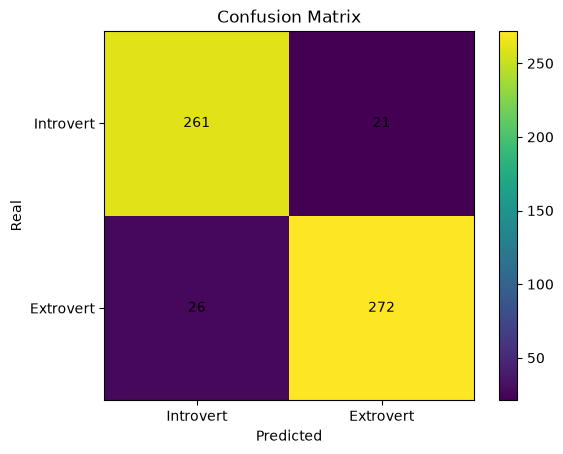

In [70]:
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Real")

plt.xticks([0, 1], ["Introvert", "Extrovert"])
plt.yticks([0, 1], ["Introvert", "Extrovert"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

In [71]:
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Introvert", "Extrovert"],
    zero_division=0
))

              precision    recall  f1-score   support

   Introvert       0.91      0.93      0.92       282
   Extrovert       0.93      0.91      0.92       298

    accuracy                           0.92       580
   macro avg       0.92      0.92      0.92       580
weighted avg       0.92      0.92      0.92       580



In [72]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

print(coefficients)

                     Feature  Coefficient
0           Time_spent_Alone     0.054163
1                 Stage_fear    -2.559257
2    Social_event_attendance     0.070524
3              Going_outside     0.002321
4  Drained_after_socializing    -2.456623
5        Friends_circle_size    -0.053606
6             Post_frequency     0.138026


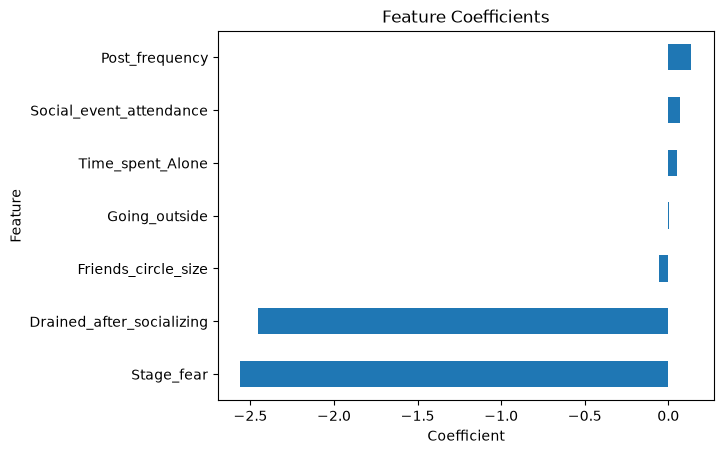

In [73]:
coefficients.sort_values("Coefficient").plot(
    kind="barh",
    x="Feature",
    y="Coefficient",
    legend=False
)

plt.title("Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.show()

In [74]:
new_person = pd.DataFrame({
    "Time_spent_Alone": [2],
    "Stage_fear": [0],
    "Social_event_attendance": [8],
    "Going_outside": [7],
    "Drained_after_socializing": [0],
    "Friends_circle_size": [12],
    "Post_frequency": [7]
})

prediction = model.predict(new_person)

if prediction[0] == 0:
    print("Predicted personality: Introvert")
else:
    print("Predicted personality: Extrovert")

Predicted personality: Extrovert


In [75]:
probability = model.predict_proba(new_person)

print("Probability of Introvert:", probability[0][0])
print("Probability of Extrovert:", probability[0][1])

Probability of Introvert: 0.053011005856871685
Probability of Extrovert: 0.9469889941431283
